# 04 · Telemetry: where is the lap time?

Car telemetry (speed, throttle, brake, gear, position on track) for the fastest race laps of the
top two finishers in a few races, from OpenF1's `car_data` and `location` endpoints at about
4 Hz. Distance along the lap is integrated from speed, so two laps can be overlaid.

The result is saved to `data/processed/telemetry.parquet` for the app.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from f1tyres import plots
from f1tyres.config import DATA_PROCESSED
from f1tyres.data import load_tables
from f1tyres.openf1 import OpenF1Client, lap_telemetry, race_sessions

plots.apply_style()
client = OpenF1Client()
results = load_tables()["results"]
RACES = [(2023, "Monaco Grand Prix"), (2024, "Italian Grand Prix"), (2025, "British Grand Prix")]

frames = []
for season, event in RACES:
    sess = race_sessions(client, season)
    sess = sess[sess["meeting_name"] == event].iloc[0]
    top2 = (results[(results["Season"] == season) & (results["EventName"] == event)]
            .sort_values("Position").head(2))
    drivers = client.get("drivers", session_key=int(sess["session_key"]))
    numbers = {d["name_acronym"]: d["driver_number"] for d in drivers}
    for drv in top2["Abbreviation"]:
        tel = lap_telemetry(client, int(sess["session_key"]), int(numbers[drv]))
        frames.append(tel.assign(Season=season, EventName=event, Driver=drv))
telemetry = pd.concat(frames, ignore_index=True)
telemetry.to_parquet(DATA_PROCESSED / "telemetry.parquet", index=False)
telemetry.groupby(["Season", "EventName", "Driver"]).agg(
    lap=("LapNumber", "first"), lap_time=("LapTime", "first"), samples=("Speed", "size"),
    top_speed=("Speed", "max"), lap_length_m=("Distance", "max")).round(1)

lap  lap_time  samples  top_speed  \
Season EventName          Driver                                      
2023   Monaco Grand Prix  ALO      43      76.7      292        284   
                          VER      23      76.6      286        270   
2024   Italian Grand Prix LEC      33      83.2      305        341   
                          PIA      53      81.9      308        339   
2025   British Grand Prix NOR      48      89.7      336        313   
                          PIA      51      89.3      330        317   

                                  lap_length_m  
Season EventName          Driver                
2023   Monaco Grand Prix  ALO           3267.1  
                          VER           3249.2  
2024   Italian Grand Prix LEC           5704.7  
                          PIA           5693.9  
2025   British Grand Prix NOR           5784.4  
                          PIA           5814.8

## Speed, throttle and brake overlay

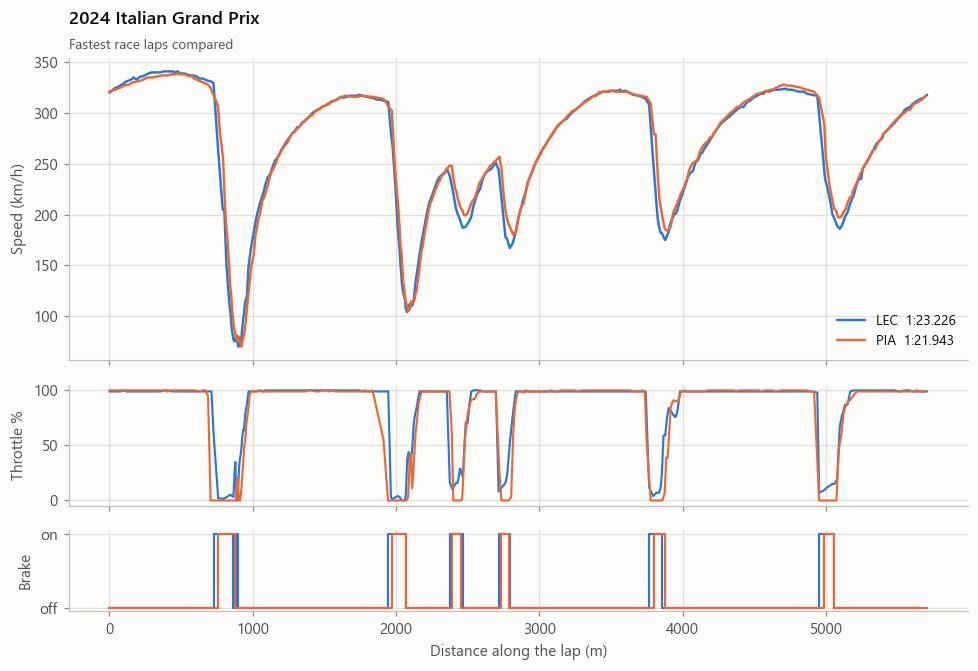

In [2]:
season, event = RACES[1]
tel = telemetry[(telemetry["Season"] == season) & (telemetry["EventName"] == event)]
drivers = tel["Driver"].unique().tolist()
fig = plots.telemetry_overlay(tel, drivers, f"{season} {event}")
plots.save(fig, "telemetry_overlay")
plt.show()

## Mini-sector dominance

Split the lap into 25 equal-distance mini-sectors and colour each by the driver who covered it
faster.

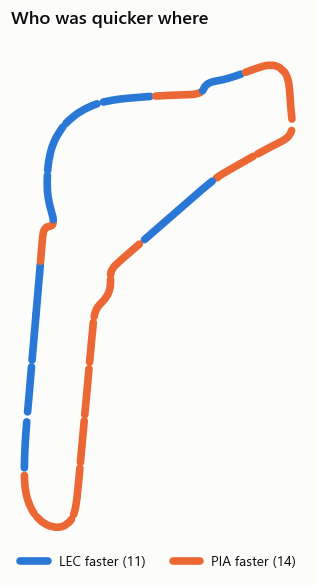

In [3]:
fig = plots.minisector_map(tel, drivers)
plots.save(fig, "minisector_map")
plt.show()

In [4]:
for (season, event), tel in telemetry.groupby(["Season", "EventName"]):
    d = tel.groupby("Driver").agg(top_speed=("Speed", "max"),
                                  full_throttle=("Throttle", lambda s: (s >= 98).mean()),
                                  braking=("Brake", "mean"))
    print(f"{season} {event}\n{d.round(2)}\n")

2023 Monaco Grand Prix
        top_speed  full_throttle  braking
Driver                                   
ALO           284           0.34     0.27
VER           270           0.32     0.26

2024 Italian Grand Prix
        top_speed  full_throttle  braking
Driver                                   
LEC           341           0.71     0.15
PIA           339           0.66     0.13

2025 British Grand Prix
        top_speed  full_throttle  braking
Driver                                   
NOR           313           0.59     0.15
PIA           317           0.60     0.15

